# Phase 4 and 5: Models and Business Questions
This notebook estimates price elasticity (Model A), a multivariate demand model (Model B), tests it out of sample, and answers the five business questions from Brainpals.

In [1]:
import os
import math
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

In [2]:
sns.set_theme(style='whitegrid')
os.makedirs('figures', exist_ok=True)

df = pd.read_csv('cleaned_master.csv')
df['week_start'] = pd.to_datetime(df['week_start'])

# Extra columns used in the models
df['trend'] = (df['week_start'] - df['week_start'].min()).dt.days // 7 + 1   # week number 1 to 104
df['has_parking_binary'] = (df['has_parking'] == 'Yes').astype(int)
df['is_beverages'] = (df['category'] == 'Beverages').astype(int)
df['is_fresh_produce'] = (df['category'] == 'Fresh Produce').astype(int)

print(f"Loaded {df.shape[0]:,} rows across {df['category'].nunique()} categories.")

Loaded 46,800 rows across 7 categories.


## Model A: Price elasticity by category
I fit `log_units ~ log_price_ratio` for each category. Because both sides are in logs, the slope is the **price elasticity**: a 1% price rise changes units sold by (slope)%. More negative means more price-sensitive.

In [3]:
rows = []
for category, data in df.groupby('category'):
    model = smf.ols('log_units ~ log_price_ratio', data=data).fit()
    low, high = model.conf_int().loc['log_price_ratio']
    rows.append({
        'category': category,
        'elasticity': round(model.params['log_price_ratio'], 3),
        'ci_95_lower': round(low, 3),
        'ci_95_upper': round(high, 3),
        'r_squared': round(model.rsquared, 3)
    })

elasticity = pd.DataFrame(rows).sort_values('elasticity').reset_index(drop=True)
elasticity.index = elasticity.index + 1   # rank 1 = most price-sensitive
elasticity

,category,elasticity,ci_95_lower,ci_95_upper,r_squared
1,Snacks,-2.832,-3.071,-2.594,0.080
2,Beverages,-2.651,-2.832,-2.469,0.081
3,Fresh Produce,-2.417,-2.628,-2.206,0.075
4,Dairy,-2.290,-2.501,-2.080,0.068
5,Personal Care,-1.963,-2.167,-1.760,0.054
6,Household,-1.864,-2.073,-1.655,0.047
7,Staples,-1.827,-2.034,-1.620,0.046


**Reading it:** all seven elasticities are below -1 and the confidence intervals do not overlap zero. Snacks and Beverages are the most price-sensitive categories, and Staples and Household the least. R-squared is low (about 5% to 8%) because price alone explains little. That is why Model B adds other factors.

## Model B: Multivariate demand model
Predictors: price ratio, promotion, store size, foot traffic, competitors, parking, temperature, rainfall, holiday week, trend and seasonality.

### Step 1: Multicollinearity check (VIF)
VIF measures how much a predictor can be predicted from the others. Above 10 is a warning sign.

In [4]:
predictors = ['log_price_ratio', 'promo_flag', 'size_sqm', 'staff_count', 'foot_traffic_index',
              'competitors_2km', 'has_parking_binary', 'avg_temp_c', 'rainfall_mm',
              'holiday_week', 'trend', 'sin_season', 'cos_season']

X = sm.add_constant(df[predictors])
vif = pd.DataFrame({
    'predictor': X.columns,
    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
vif = vif[vif['predictor'] != 'const'].sort_values('VIF', ascending=False).round(2)
print(vif.to_string(index=False))
print()
print('Correlation between size_sqm and staff_count:', round(df['size_sqm'].corr(df['staff_count']), 3))

         predictor   VIF
          size_sqm 33.08
       staff_count 32.68
        avg_temp_c  7.22
        cos_season  6.99
        sin_season  4.81
       rainfall_mm  3.92
   log_price_ratio  3.41
        promo_flag  3.33
             trend  1.30
foot_traffic_index  1.25
   competitors_2km  1.15
      holiday_week  1.14
has_parking_binary  1.07

Correlation between size_sqm and staff_count: 0.983


**The collinear pair is `size_sqm` and `staff_count`** (VIF about 33 each, correlation near 1). Bigger stores simply have more staff, so the model cannot separate their effects. I compare a model with both against one that keeps only `size_sqm`.

In [5]:
formula_with_staff = 'log_units ~ log_price_ratio + promo_flag + size_sqm + staff_count + foot_traffic_index + competitors_2km + C(has_parking) + avg_temp_c + rainfall_mm + holiday_week + trend + sin_season + cos_season'
formula_clean = 'log_units ~ log_price_ratio + promo_flag + size_sqm + foot_traffic_index + competitors_2km + C(has_parking) + avg_temp_c + rainfall_mm + holiday_week + trend + sin_season + cos_season'

model_with_staff = smf.ols(formula_with_staff, data=df).fit()
model_clean = smf.ols(formula_clean, data=df).fit()

pd.DataFrame({
    'with staff_count': [model_with_staff.rsquared, model_with_staff.aic, model_with_staff.params['size_sqm'], model_with_staff.bse['size_sqm']],
    'without staff_count': [model_clean.rsquared, model_clean.aic, model_clean.params['size_sqm'], model_clean.bse['size_sqm']]
}, index=['R-squared', 'AIC', 'size_sqm coefficient', 'size_sqm standard error']).round(7)

,with staff_count,without staff_count
R-squared,0.719555,0.719370
AIC,33298.125468,33327.012778
size_sqm coefficient,0.000570,0.000665
size_sqm standard error,0.000017,0.000003


**Reading it:** dropping `staff_count` leaves the fit practically unchanged (R-squared 0.7196 vs 0.7194) but makes the `size_sqm` estimate far more precise (its standard error falls about five times). I keep the model without `staff_count`.

### Step 2: Residual diagnostics and Breusch-Pagan test

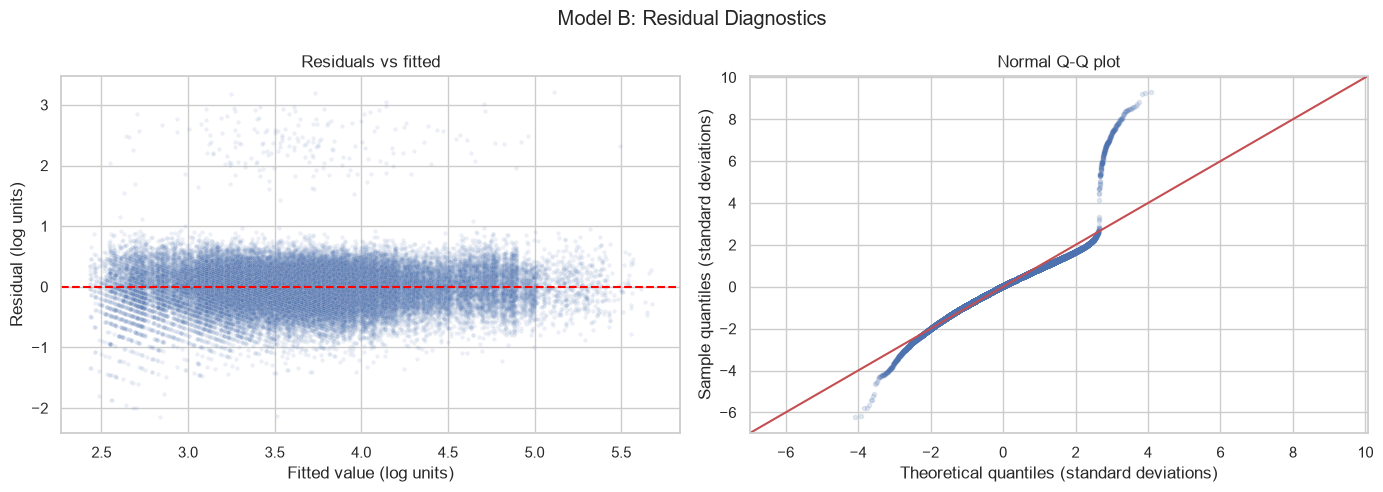

Breusch-Pagan: LM = 96.66, p-value = 2.50e-15
Heteroscedasticity found: using robust (HC3) standard errors.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=model_clean.fittedvalues, y=model_clean.resid, alpha=0.1, s=10, ax=axes[0])
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set(title='Residuals vs fitted', xlabel='Fitted value (log units)', ylabel='Residual (log units)')

sm.qqplot(model_clean.resid, line='45', fit=True, ax=axes[1], markersize=3, alpha=0.15)
axes[1].set(title='Normal Q-Q plot', xlabel='Theoretical quantiles (standard deviations)', ylabel='Sample quantiles (standard deviations)')

plt.suptitle('Model B: Residual Diagnostics')
plt.tight_layout()
plt.savefig('figures/model_b_diagnostics.png', dpi=300)
plt.show()

lm_stat, lm_p, f_stat, f_p = het_breuschpagan(model_clean.resid, model_clean.model.exog)
print(f"Breusch-Pagan: LM = {lm_stat:.2f}, p-value = {lm_p:.2e}")
if lm_p < 0.05:
    print('Heteroscedasticity found: using robust (HC3) standard errors.')
else:
    print('No heteroscedasticity found: ordinary standard errors are fine.')

In [7]:
model_robust = smf.ols(formula_clean, data=df).fit(cov_type='HC3')

pd.DataFrame({
    'coefficient': model_clean.params,
    'OLS std error': model_clean.bse,
    'HC3 std error': model_robust.bse,
    'HC3 p-value': model_robust.pvalues
}).round(5)

,coefficient,OLS std error,HC3 std error,HC3 p-value
Intercept,1.92679,0.04986,0.04967,0.00000
C(has_parking)[T.Yes],0.14585,0.00327,0.00323,0.00000
log_price_ratio,-1.25318,0.04066,0.04042,0.00000
promo_flag,0.22783,0.00759,0.00759,0.00000
size_sqm,0.00066,0.00000,0.00000,0.00000
foot_traffic_index,0.00994,0.00007,0.00008,0.00000
competitors_2km,-0.07832,0.00086,0.00088,0.00000
avg_temp_c,0.00674,0.00162,0.00161,0.00003
rainfall_mm,-0.00020,0.00008,0.00008,0.00963
holiday_week,0.16630,0.00640,0.00614,0.00000


**Reading it:** the Breusch-Pagan test is strongly significant, so the spread of the errors is not constant. The HC3 standard errors are almost the same as the ordinary ones, so every conclusion holds. The Q-Q plot shows the middle of the residuals following the line, with some deviation in the tails.

### Step 3: Interaction terms
An interaction lets an effect differ by group. I test each one with an F-test against the base model (p below 0.05 means the extra terms improve it).

In [8]:
base = smf.ols(formula_clean, data=df).fit()

interaction_formulas = {
    'promo x category': formula_clean + ' + C(category) + promo_flag:C(category)',
    'temperature x Beverages': formula_clean + ' + is_beverages + avg_temp_c:is_beverages',
    'rainfall x Fresh Produce': formula_clean + ' + is_fresh_produce + rainfall_mm:is_fresh_produce',
    'all three': formula_clean + ' + C(category) + promo_flag:C(category) + avg_temp_c:is_beverages + rainfall_mm:is_fresh_produce'
}

rows = [{'model': 'Base Model B', 'R-squared': base.rsquared, 'adj R-squared': base.rsquared_adj,
         'AIC': base.aic, 'BIC': base.bic, 'F-test p-value': None, 'improves model?': ''}]

for name, formula in interaction_formulas.items():
    model = smf.ols(formula, data=df).fit()
    p_value = sm.stats.anova_lm(base, model)['Pr(>F)'].iloc[1]
    rows.append({'model': name, 'R-squared': model.rsquared, 'adj R-squared': model.rsquared_adj,
                 'AIC': model.aic, 'BIC': model.bic, 'F-test p-value': p_value,
                 'improves model?': 'Yes' if p_value < 0.05 and model.aic < base.aic else 'No'})

pd.DataFrame(rows).round(4)

,model,R-squared,adj R-squared,AIC,BIC,F-test p-value,improves model?
0,Base Model B,0.7194,0.7193,33327.0128,33440.8101,NaN,
1,promo x category,0.7214,0.7212,33013.5997,33232.4407,0.0,Yes
2,temperature x Beverages,0.7227,0.7226,32771.2747,32902.5793,0.0,Yes
3,rainfall x Fresh Produce,0.7200,0.7199,33223.2218,33354.5264,0.0,Yes
4,all three,0.7252,0.7250,32373.6212,32609.9694,0.0,Yes


**Reading it:** all three interactions are statistically significant and lower the AIC, so each improves the model. The gains in R-squared are small (0.7194 to 0.7252 with all three), so the effects are real but modest. Temperature matters more for Beverages, and rain matters more for Fresh Produce.

### Step 4: Out-of-sample test (train on weeks 1 to 80, test on weeks 81 to 104)
The split is by time, so the model never sees the future. The naive baseline predicts this week's log units with the log of units sold four weeks earlier (the lag was built within each store-product pair).

In [9]:
train = df[df['trend'] <= 80]
test = df[df['trend'] > 80]
print(f"Train: {len(train):,} rows (weeks 1-80). Test: {len(test):,} rows (weeks 81-104).")

model_b_train = smf.ols(formula_clean, data=train).fit()
model_all_train = smf.ols(interaction_formulas['all three'], data=train).fit()

predictions = {
    'Naive lag-4 baseline': test['units_lag_4'].apply(math.log),
    'Model B': model_b_train.predict(test),
    'Model B + interactions': model_all_train.predict(test)
}

def score(actual, predicted):
    error = actual - predicted
    rmse = (error ** 2).mean() ** 0.5
    mae = error.abs().mean()
    r2 = 1 - (error ** 2).sum() / ((actual - actual.mean()) ** 2).sum()
    return rmse, mae, r2

results = pd.DataFrame(
    [score(test['log_units'], predicted) for predicted in predictions.values()],
    index=predictions.keys(), columns=['RMSE', 'MAE', 'R-squared']
).round(4)
results

Train: 36,000 rows (weeks 1-80). Test: 10,800 rows (weeks 81-104).


,RMSE,MAE,R-squared
Naive lag-4 baseline,0.5202,0.3870,0.3516
Model B,0.3467,0.2497,0.7120
Model B + interactions,0.3435,0.2469,0.7173


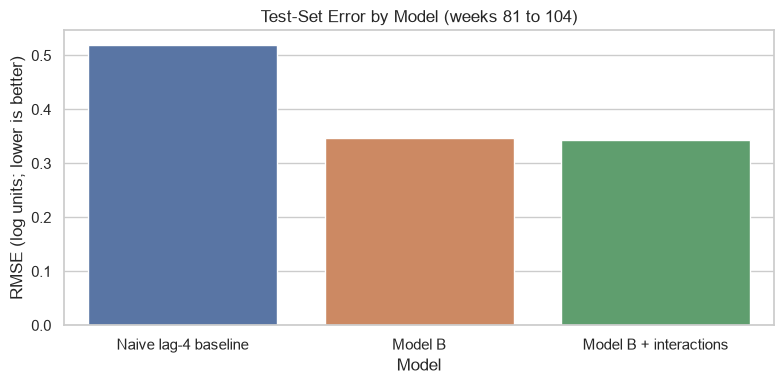

In [10]:
plot_data = results.reset_index().rename(columns={'index': 'model'})

plt.figure(figsize=(8, 4))
sns.barplot(data=plot_data, x='model', y='RMSE', hue='model', legend=False)
plt.title('Test-Set Error by Model (weeks 81 to 104)')
plt.xlabel('Model')
plt.ylabel('RMSE (log units; lower is better)')
plt.tight_layout()
plt.savefig('figures/model_test_rmse.png', dpi=300)
plt.show()

**Reading it:** Model B cuts the test error by about a third compared with the naive baseline (RMSE 0.347 vs 0.520) and lifts out-of-sample R-squared from 0.35 to 0.71. The interactions add only a little more (0.717). So the simple Model B captures most of the value.

# Phase 5: Business Questions

## Question 1: Which category benefits most from promotions, and does any promotion lose money?
I compare average gross profit per store-product-week in promotion weeks and non-promotion weeks. The **break-even lift** is the volume increase a promotion needs just to keep profit unchanged, given the lower profit per unit.

In [11]:
def promo_table(by):
    means = df.groupby(by + ['promo_flag'])[['units_sold', 'gross_profit']].mean().unstack()
    out = pd.DataFrame({
        'units_base': means['units_sold'][0], 'units_promo': means['units_sold'][1],
        'profit_base': means['gross_profit'][0], 'profit_promo': means['gross_profit'][1]
    })
    out['volume_lift_pct'] = (out['units_promo'] / out['units_base'] - 1) * 100
    out['breakeven_lift_pct'] = ((out['profit_base'] / out['units_base']) / (out['profit_promo'] / out['units_promo']) - 1) * 100
    out['profit_change_pct'] = (out['profit_promo'] / out['profit_base'] - 1) * 100
    out['verdict'] = out['profit_change_pct'].apply(lambda x: 'Loses money' if x < 0 else 'Makes money')
    return out.round(1)

by_category = promo_table(['category']).sort_values('profit_change_pct', ascending=False)
by_product = promo_table(['category', 'product_id']).sort_values('profit_change_pct', ascending=False)

print(by_category[['volume_lift_pct', 'breakeven_lift_pct', 'profit_change_pct', 'verdict']].to_string())
print()
print(by_product[['volume_lift_pct', 'breakeven_lift_pct', 'profit_change_pct', 'verdict']].to_string())

               volume_lift_pct  breakeven_lift_pct  profit_change_pct      verdict
category                                                                          
Beverages                 63.0                41.0               15.5  Makes money
Snacks                    64.4                48.9               10.4  Makes money
Dairy                     50.9                45.1                4.0  Makes money
Fresh Produce             56.0                56.0                0.0  Makes money
Personal Care             38.8                38.9               -0.1  Loses money
Household                 40.5                46.0               -3.8  Loses money
Staples                   41.6                52.4               -7.1  Loses money

                          volume_lift_pct  breakeven_lift_pct  profit_change_pct      verdict
category      product_id                                                                     
Beverages     P003                   68.4                40.7   

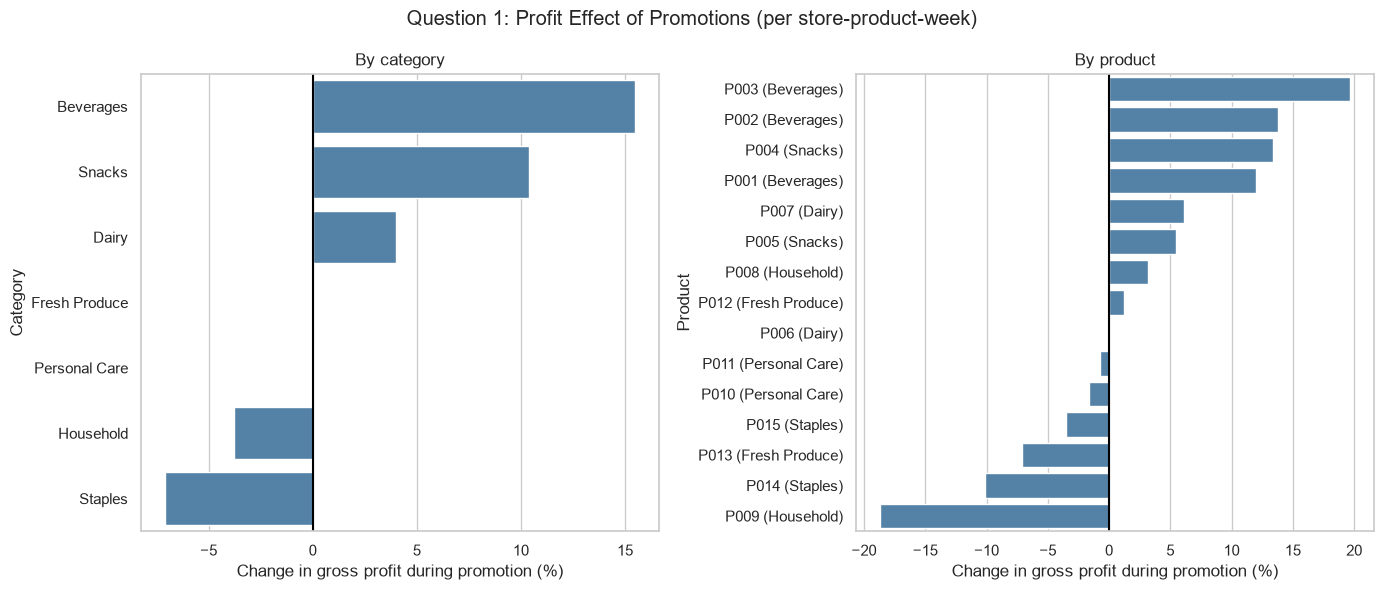

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(data=by_category.reset_index(), y='category', x='profit_change_pct', color='steelblue', ax=axes[0])
axes[0].axvline(0, color='black')
axes[0].set(title='By category', xlabel='Change in gross profit during promotion (%)', ylabel='Category')

product_plot = by_product.reset_index()
product_plot['product'] = product_plot['product_id'] + ' (' + product_plot['category'] + ')'
sns.barplot(data=product_plot, y='product', x='profit_change_pct', color='steelblue', ax=axes[1])
axes[1].axvline(0, color='black')
axes[1].set(title='By product', xlabel='Change in gross profit during promotion (%)', ylabel='Product')

plt.suptitle('Question 1: Profit Effect of Promotions (per store-product-week)')
plt.tight_layout()
plt.savefig('figures/fig_q1_promo_profit.png', dpi=300)
plt.show()

**Answer.** **Beverages benefit most**: in promotion weeks their gross profit per store-product-week is **15.5% higher** (volume +63.0% against a break-even lift of only 41.0%). Snacks come next (+10.4%), then Dairy (+4.0%). Fresh Produce breaks even (0.0%).

**Yes, some promotions lose money.** Staples (-7.1%), Household (-3.8%) and Personal Care (-0.1%) lose profit. At product level, **7 of 15 products lose money**: P009, P014, P013, P015, P010, P011 and P006. The worst is **P009 (Household)**: it needed a 65.6% volume lift to break even but delivered only 34.6%, so profit falls 18.7%.

*Caveat: this compares promotion weeks with non-promotion weeks directly and does not control for when promotions were run.*

## Question 2: What is the revenue-maximising discount level per category?
For each category I estimate how units respond to the discount (`log_units ~ discount_pct` plus the Model B controls). Revenue per unit falls as `(1 - discount)`, while units rise by `exp(beta x discount)`. Multiplying gives a **revenue index** (1.00 = no discount), which I compute for every discount level in the data (0% to 30%). I also show a profit index, using each category's cost as a share of list price.

In [13]:
discounts = [0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
controls = ('size_sqm + foot_traffic_index + competitors_2km + C(has_parking) + avg_temp_c + '
            'rainfall_mm + holiday_week + trend + sin_season + cos_season')

rows = []
betas = {}
for category, data in df.groupby('category'):
    model = smf.ols('log_units ~ discount_pct + ' + controls, data=data).fit()
    beta = model.params['discount_pct']
    betas[category] = round(beta, 2)
    cost_share = (data['unit_cost_ngn'] / data['list_price_ngn']).mean()
    for d in discounts:
        units_index = math.exp(beta * d)
        rows.append({
            'category': category,
            'discount_pct': d * 100,
            'revenue_index': (1 - d) * units_index,
            'profit_index': units_index * ((1 - d) - cost_share) / (1 - cost_share)
        })

curves = pd.DataFrame(rows)

best_revenue = curves.loc[curves.groupby('category')['revenue_index'].idxmax(), ['category', 'discount_pct', 'revenue_index']]
best_profit = curves.loc[curves.groupby('category')['profit_index'].idxmax(), ['category', 'discount_pct', 'profit_index']]

answer = best_revenue.merge(best_profit, on='category', suffixes=('_revenue', '_profit'))
answer['discount_beta'] = answer['category'].map(betas)
answer.round(2).rename(columns={'discount_pct_revenue': 'revenue-maximising discount (%)',
                                'discount_pct_profit': 'profit-maximising discount (%)'})

,category,revenue-maximising discount (%),revenue_index,profit-maximising discount (%),profit_index,discount_beta
0,Beverages,30.0,1.75,5.0,1.01,3.06
1,Dairy,30.0,1.49,0.0,1.00,2.52
2,Fresh Produce,30.0,1.60,0.0,1.00,2.75
3,Household,30.0,1.36,0.0,1.00,2.21
4,Personal Care,30.0,1.38,0.0,1.00,2.27
5,Snacks,30.0,1.87,0.0,1.00,3.27
6,Staples,30.0,1.24,0.0,1.00,1.91


Observations at each discount level:
discount_pct
0     34538
5      5110
10     2477
15     2102
20     1690
25        8
30      875


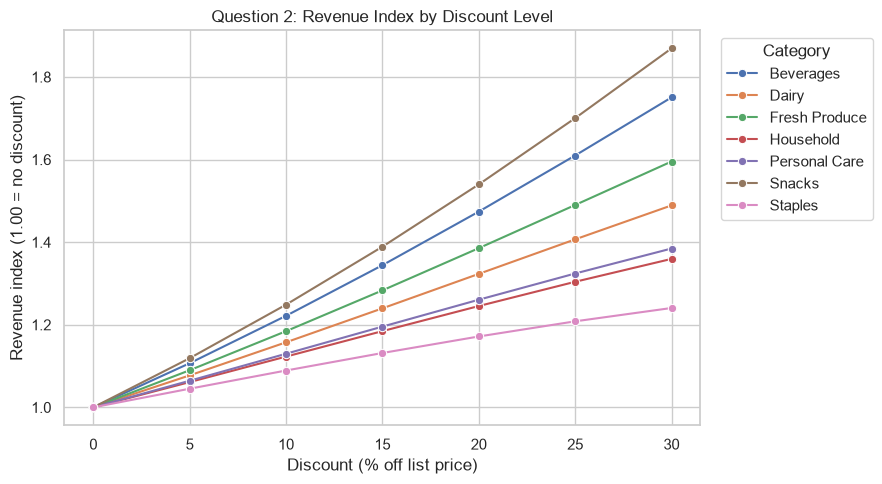

In [14]:
print('Observations at each discount level:')
print((df['discount_pct'] * 100).round().astype(int).value_counts().sort_index().to_string())

plt.figure(figsize=(9, 5))
sns.lineplot(data=curves, x='discount_pct', y='revenue_index', hue='category', marker='o')
plt.title('Question 2: Revenue Index by Discount Level')
plt.xlabel('Discount (% off list price)')
plt.ylabel('Revenue index (1.00 = no discount)')
plt.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('figures/fig_q2_revenue_vs_discount.png', dpi=300)
plt.show()

**Answer.** For **all seven categories, revenue is highest at the deepest discount in the data, 30%**. Every category's discount response (beta) is above 1 (1.9 for Staples up to 3.3 for Snacks), so each extra point of discount adds more units than it costs in price. The revenue index at 30% ranges from 1.24 (Staples) to 1.87 (Snacks), meaning 24% to 87% more revenue than at no discount.

**Important limits:** (1) 30% is the edge of the data, not a true peak. The maths puts the peak between 48% and 69%, which is outside what Brainpals has tried, so the result is "the deepest discount tested", not a proven optimum. (2) Only 8 rows have a 25% discount, so that point is unreliable. (3) **Revenue is not profit**: the profit index peaks at 0% for six categories and 5% for Beverages, because deep discounts eat the margin (see Question 1). Brainpals should not choose discounts on revenue alone.

## Question 3: Which 5 stores underperform what their size, traffic and competition predict?
Model B already includes size, foot traffic and competitors. For each store I average the model's residuals (actual minus predicted log units) over all its rows. A negative average means the store sells less than the model expects. A residual in log units converts to a percentage with `exp(residual) - 1`.

In [15]:
df['residual'] = model_clean.resid

store_gap = df.groupby('store_id').agg(
    mean_residual=('residual', 'mean'),
    std_residual=('residual', 'std'),
    rows=('residual', 'size'),
    city=('city', 'first'),
    store_type=('store_type', 'first'),
    size_sqm=('size_sqm', 'first'),
    foot_traffic=('foot_traffic_index', 'first'),
    competitors=('competitors_2km', 'first')
).reset_index()

store_gap['gap_vs_prediction_pct'] = store_gap['mean_residual'].apply(lambda r: (math.exp(r) - 1) * 100)
store_gap['t_statistic'] = store_gap['mean_residual'] / (store_gap['std_residual'] / store_gap['rows'] ** 0.5)
store_gap = store_gap.sort_values('gap_vs_prediction_pct').reset_index(drop=True)

store_gap.head(5)[['store_id', 'city', 'store_type', 'size_sqm', 'foot_traffic', 'competitors',
                   'gap_vs_prediction_pct', 't_statistic']].round(1)

,store_id,city,store_type,size_sqm,foot_traffic,competitors,gap_vs_prediction_pct,t_statistic
0,S04,Lagos,Standard,834,149.3,5,-21.0,-27.9
1,S19,Port Harcourt,Hypermarket,1938,154.4,5,-12.1,-16.8
2,S17,Abuja,Express,264,94.2,1,-11.4,-14.1
3,S18,Ibadan,Express,314,102.6,2,-11.2,-13.4
4,S14,Kano,Express,228,83.3,2,-8.3,-10.0


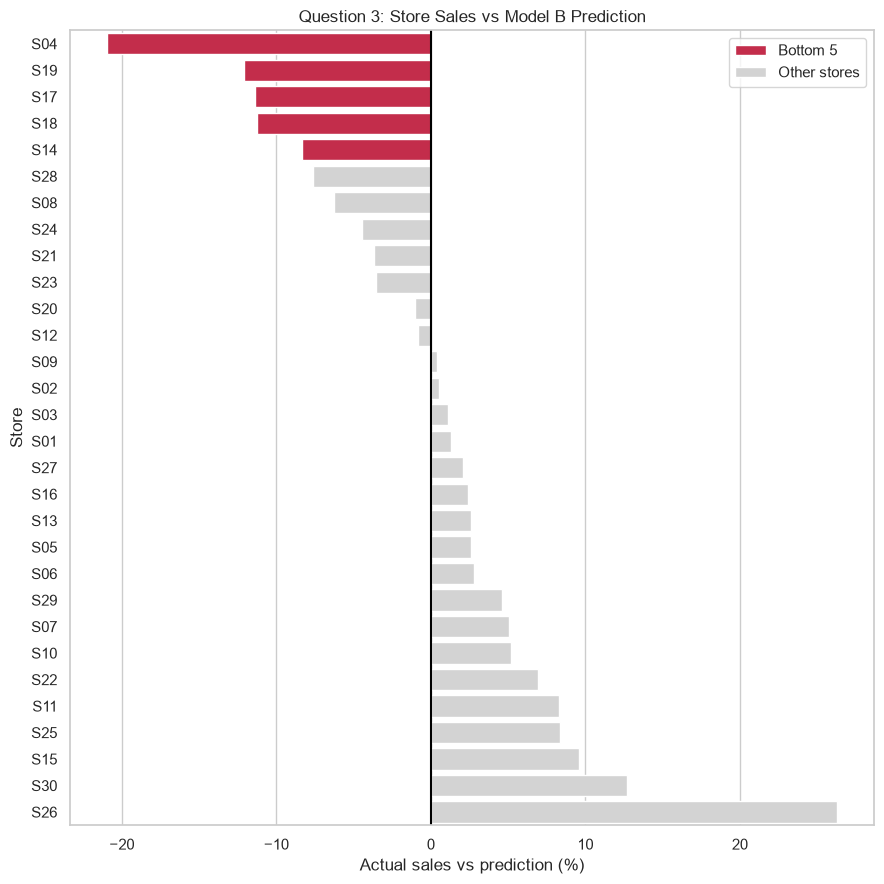

In [16]:
store_gap['group'] = store_gap.index.map(lambda i: 'Bottom 5' if i < 5 else 'Other stores')

plt.figure(figsize=(9, 9))
sns.barplot(data=store_gap, y='store_id', x='gap_vs_prediction_pct', hue='group',
            palette={'Bottom 5': 'crimson', 'Other stores': 'lightgray'}, dodge=False)
plt.axvline(0, color='black')
plt.title('Question 3: Store Sales vs Model B Prediction')
plt.xlabel('Actual sales vs prediction (%)')
plt.ylabel('Store')
plt.legend(title='')
plt.tight_layout()
plt.savefig('figures/fig_q3_store_residuals.png', dpi=300)
plt.show()

**Answer.** The five stores furthest below what Model B predicts from their size, foot traffic and competition are:

| Store | City | Type | Sales vs prediction |
|---|---|---|---|
| S04 | Lagos | Standard | -21.0% |
| S19 | Port Harcourt | Hypermarket | -12.1% |
| S17 | Abuja | Express | -11.4% |
| S18 | Ibadan | Express | -11.2% |
| S14 | Kano | Express | -8.3% |

Each gap is statistically very strong (t-statistics between -10 and -28). Because size, traffic and competitors are already in the model, these gaps point to something else: management, layout, stock availability or local factors. S04 should be investigated first.

## Question 4: How much weekly revenue growth is real volume and how much is inflation?
I compare the average of the first 13 weeks with the average of the last 13 weeks. Nominal revenue = units x average price per unit. Average price per unit then splits into general inflation (CPI) and a leftover "price and mix" effect (promotions, product mix). Shares are measured in logs so that they add to 100%.

In [17]:
weekly = df.groupby('week_start').agg(
    revenue=('revenue_ngn', 'sum'), units=('units_sold', 'sum'), cpi=('cpi_index', 'mean')
).reset_index()
weekly['real_revenue'] = weekly['revenue'] / weekly['cpi'] * 100

first = weekly.head(13).mean(numeric_only=True)
last = weekly.tail(13).mean(numeric_only=True)

nominal = last['revenue'] / first['revenue'] - 1
volume = last['units'] / first['units'] - 1
price_per_unit = (last['revenue'] / last['units']) / (first['revenue'] / first['units']) - 1
inflation = last['cpi'] / first['cpi'] - 1
real = last['real_revenue'] / first['real_revenue'] - 1
price_mix = (1 + price_per_unit) / (1 + inflation) - 1

def share(growth):
    return math.log(1 + growth) / math.log(1 + nominal) * 100

summary = pd.DataFrame({
    'growth_pct': [nominal * 100, volume * 100, price_per_unit * 100, inflation * 100, price_mix * 100, real * 100],
    'share_of_nominal_growth_pct': [100, share(volume), share(price_per_unit), share(inflation), share(price_mix), None]
}, index=['Nominal revenue', 'Real volume (units sold)', 'Average price per unit', 'Inflation (CPI)',
          'Price and mix beyond inflation', 'Real revenue (CPI-adjusted)']).round(1)
summary

,growth_pct,share_of_nominal_growth_pct
Nominal revenue,71.5,100.0
Real volume (units sold),17.8,30.3
Average price per unit,45.7,69.7
Inflation (CPI),52.7,78.4
Price and mix beyond inflation,-4.6,-8.7
Real revenue (CPI-adjusted),12.4,NaN


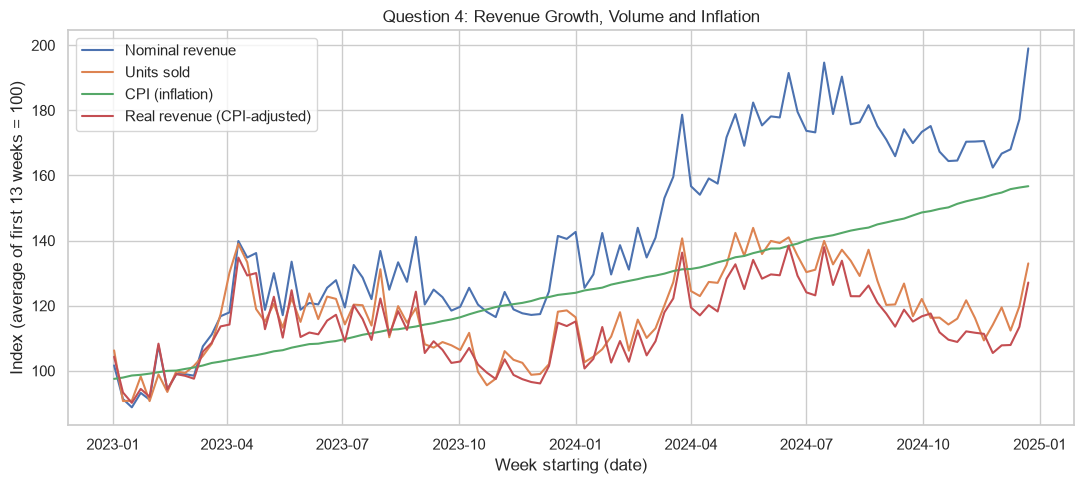

In [18]:
indexed = weekly.copy()
for column in ['revenue', 'units', 'cpi', 'real_revenue']:
    indexed[column] = indexed[column] / first[column] * 100

indexed = indexed.rename(columns={'revenue': 'Nominal revenue', 'units': 'Units sold',
                                  'cpi': 'CPI (inflation)', 'real_revenue': 'Real revenue (CPI-adjusted)'})
indexed = indexed.melt(id_vars='week_start', value_vars=['Nominal revenue', 'Units sold', 'CPI (inflation)',
                                                         'Real revenue (CPI-adjusted)'],
                       var_name='measure', value_name='index')

plt.figure(figsize=(11, 5))
sns.lineplot(data=indexed, x='week_start', y='index', hue='measure')
plt.title('Question 4: Revenue Growth, Volume and Inflation')
plt.xlabel('Week starting (date)')
plt.ylabel('Index (average of first 13 weeks = 100)')
plt.legend(title='')
plt.tight_layout()
plt.savefig('figures/fig_q4_growth_decomposition.png', dpi=300)
plt.show()

**Answer.** Comparing the first 13 weeks with the last 13, **nominal revenue grew 71.5%**. Of that growth (measured in logs so shares add to 100%):
- **Real volume growth (units sold, +17.8%) explains about 30%.**
- **Inflation explains about 78%**: CPI rose 52.7%, and average price per unit rose 45.7%.
- Prices rose slightly *less* than CPI (price and mix effect -4.6%, about -9% of the growth), probably because of promotions and product mix.

After removing inflation, **real revenue grew 12.4%**. In short, roughly **70% of headline revenue growth is just higher prices**, and only about 30% is customers buying more.

## Question 5: Which customer segments are at risk of churning, and what are the top three drivers?
The Customers sheet records whether each customer actually left in the next 90 days (`churned_next_90d`). I (1) group customers into RFM segments (Recency, Frequency, Monetary value, each scored 1 to 4) and compare their churn rates, and (2) fit a logistic regression to find the strongest drivers.

In [19]:
customers = pd.read_excel('Brainpals_sales_analytics.xlsx', sheet_name='Customers')
customers['age'] = customers['age'].where(customers['age'].between(1, 100))   # impossible ages become blank

# RFM scores: 4 is best. Recency: fewer days since the last visit is better.
customers['R'] = pd.qcut(customers['days_since_last_visit'], q=4, labels=[4, 3, 2, 1]).astype(int)
customers['F'] = pd.qcut(customers['visits_12m'].rank(method='first'), q=4, labels=[1, 2, 3, 4]).astype(int)
customers['M'] = pd.qcut(customers['total_spend_12m_ngn'].rank(method='first'), q=4, labels=[1, 2, 3, 4]).astype(int)

def segment(row):
    if row['R'] >= 3 and row['F'] >= 3 and row['M'] >= 3:
        return 'Champions'
    elif row['R'] >= 3 and row['F'] <= 2:
        return 'Recent / Promising'
    elif row['R'] <= 2 and (row['F'] >= 3 or row['M'] >= 3):
        return 'At Risk (high value, inactive)'
    elif row['R'] <= 2 and row['F'] <= 2 and row['M'] <= 2:
        return 'Hibernating'
    else:
        return 'Standard Active'

customers['segment'] = customers.apply(segment, axis=1)

segments = customers.groupby('segment').agg(
    customers=('customer_id', 'count'),
    churn_rate_pct=('churned_next_90d', lambda s: s.mean() * 100),
    total_spend_m_ngn=('total_spend_12m_ngn', lambda s: s.sum() / 1e6)
).sort_values('churn_rate_pct', ascending=False).round(1)

print(f"Overall churn rate: {customers['churned_next_90d'].mean() * 100:.1f}%")
print()
print(segments)
print()
print(customers.groupby('loyalty_tier')['churned_next_90d'].mean().mul(100).round(1).to_string())

Overall churn rate: 17.6%

                                customers  churn_rate_pct  total_spend_m_ngn
segment                                                                     
Hibernating                           356            37.4               57.2
At Risk (high value, inactive)        522            18.2              200.7
Recent / Promising                    447            14.3               95.7
Standard Active                       101             6.9               21.8
Champions                             374             4.5              172.8

loyalty_tier
Bronze    24.9
Gold       7.3
Silver    11.9


In [23]:
# Logistic regression. Total spend is left out because it equals visits x basket size.
features = ['days_since_last_visit', 'visits_12m', 'avg_basket_ngn', 'discount_usage_ratio',
            'tenure_yrs', 'age', 'loyalty_member']

model_data = customers[features + ['churned_next_90d']].copy()
model_data['loyalty_member'] = (model_data['loyalty_member'] == 'Yes').astype(int)
model_data = model_data.dropna()

# Standardise every driver so the coefficients can be compared fairly
for column in features:
    model_data[column] = (model_data[column] - model_data[column].mean()) / model_data[column].std()

logit = smf.logit('churned_next_90d ~ ' + ' + '.join(features), data=model_data).fit(disp=0)

drivers = pd.DataFrame({
    'driver': features,
    'coefficient': logit.params[features].values,
    'odds_ratio': logit.params[features].apply(math.exp).values,
    'p_value': logit.pvalues[features].values
})
drivers['strength'] = drivers['coefficient'].abs()
drivers = drivers.sort_values('strength', ascending=False).drop(columns='strength').reset_index(drop=True)

print(f"Customers used: {len(model_data):,}. Pseudo R-squared: {logit.prsquared:.3f}")
drivers.round(3)

Customers used: 1,689. Pseudo R-squared: 0.175


,driver,coefficient,odds_ratio,p_value
0,days_since_last_visit,0.838,2.311,0.000
1,visits_12m,-0.586,0.557,0.000
2,loyalty_member,-0.258,0.772,0.000
3,avg_basket_ngn,-0.141,0.868,0.055
4,discount_usage_ratio,0.103,1.109,0.146
5,age,-0.058,0.944,0.415
6,tenure_yrs,0.033,1.033,0.652


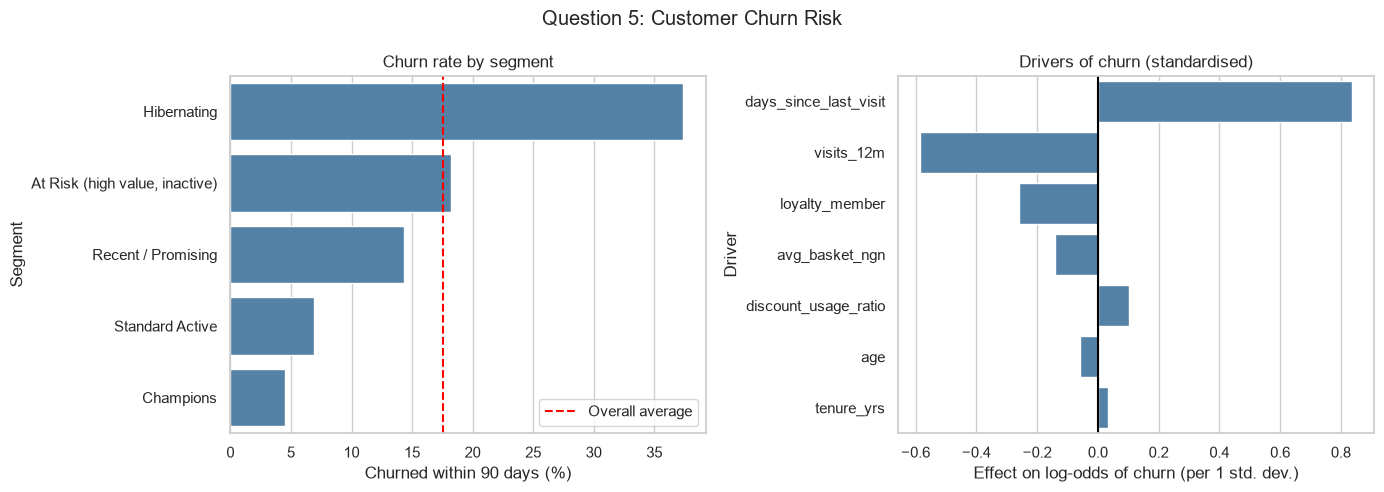

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=segments.reset_index(), y='segment', x='churn_rate_pct', color='steelblue', ax=axes[0])
axes[0].axvline(customers['churned_next_90d'].mean() * 100, color='red', linestyle='--', label='Overall average')
axes[0].set(title='Churn rate by segment', xlabel='Churned within 90 days (%)', ylabel='Segment')
axes[0].legend()

sns.barplot(data=drivers, y='driver', x='coefficient', color='steelblue', ax=axes[1])
axes[1].axvline(0, color='black')
axes[1].set(title='Drivers of churn (standardised)', xlabel='Effect on log-odds of churn (per 1 std. dev.)', ylabel='Driver')

plt.suptitle('Question 5: Customer Churn Risk')
plt.tight_layout()
plt.savefig('figures/fig_q5_churn_drivers.png', dpi=300)
plt.show()

**Answer: which segments.** Overall, 17.6% of customers churned within 90 days. **Hibernating customers are the most at risk (37.4% churn)**, followed by the "At Risk" high-value group (18.2%, only slightly above average, but it holds the largest spend: 200.7 million NGN across 522 customers). Recent / Promising customers churn at 14.3%, Standard Active at 6.9% and Champions at 4.5%. By loyalty tier, Bronze churn is 24.9%, Silver 11.9% and Gold 7.3%.

**Answer: top three drivers** (logistic regression, 1,689 customers, effects per one standard deviation):
1. **Days since last visit** (odds ratio 2.31): the longer since the last visit, the much higher the churn odds.
2. **Number of visits in 12 months** (odds ratio 0.56): frequent shoppers are far less likely to leave.
3. **Loyalty membership** (odds ratio 0.77): members are less likely to leave.

All three are statistically significant (p below 0.001). Average basket size is a weaker fourth driver (p = 0.055), and age, tenure and discount usage are not significant. Practical meaning: contact customers who have gone quiet, and move occasional shoppers into the loyalty programme.